# NIÑO-PREDICT — Exploratory Data Analysis (EDA)
## Agricultural Estimations & Climate Impact Modeling
This notebook implements **Stage 1 (Ingestion & Schema Cleaning)** and **Stage 2 (Audit & Data Hygiene)** of the exploratory data analysis pipeline for `Estimaciones.csv`.

### Objectives
1. **Stage 1: Ingestion & Schema Cleaning**
   - Robust loading of Latin-1 encoded, semicolon-delimited CSV.
   - Column renaming to clean `snake_case` standards.
   - String normalization (`provincia`, `departamento`, `cultivo`).
   - Temporal decomposition of agricultural seasons (`campana` $\rightarrow$ `anio_inicio`, `anio_fin`).
2. **Stage 2: Audit & Data Hygiene**
   - Profile nulls and implicit missingness.
   - Audit and classify zeros: distinguishing **inactive placeholders** from **total climate loss events**.
   - Audit physical boundaries ($	ext{sup\_cosechada} \le 	ext{sup\_sembrada}$).
   - Derive climate-risk indicators: `sup_perdida_ha` and `tasa_perdida`.
   - Validate mathematical consistency of reported yield vs. calculated yield.
   - Generate filtered production dataset `df_clean` ready for El Niño correlation analysis.


In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Styling and options
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 1000)
pd.set_option('display.precision', 15)

print("Setup completed successfully.")


Setup completed successfully.


---
## Stage 1: Ingestion & Schema Cleaning

We ingest `data/raw/Estimaciones.csv`.
- Delimiter: `;` (semicolon)
- Encoding: `latin1` / `cp1252` (handling Spanish accents and ñ)
- Initial blank line handling


In [39]:
# Locate raw dataset relative to workspace or notebook folder
possible_paths = [
    Path('../data/raw/Estimaciones.csv'),
    Path('data/raw/Estimaciones.csv')
]

data_path = next((p for p in possible_paths if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Could not find data/raw/Estimaciones.csv")

print(f"Loading data from: {data_path.resolve()}")

df_raw = pd.read_csv(
    data_path,
    sep=';',
    encoding='latin1',
    skipinitialspace=True
)

print(f"Raw shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"Raw memory usage: {df_raw.memory_usage().sum() / (1024**2):.2f} MB")
df_raw.head(3)


Loading data from: C:\Users\nico_\OneDrive\Desktop\PROYECTOS\NIÑO-PREDICT\data\raw\Estimaciones.csv
Raw shape: 163,593 rows x 12 columns
Raw memory usage: 14.98 MB


,ID Provincia,Provincia,ID Departamento,Departamento,Id Cultivo,Cultivo,ID Campaña,Campana,Sup. Sembrada (Ha),Sup. Cosechada (Ha),Producción (Tn),Rendimiento (Kg/Ha)
0,6,BUENOS AIRES,854,25 DE MAYO,1,Ajo,1,1969/70,3,3,10,3333
1,6,BUENOS AIRES,854,25 DE MAYO,1,Ajo,2,1970/71,1,1,3,3000
2,6,BUENOS AIRES,14,ADOLFO GONZALES CHAVES,1,Ajo,1,1969/70,15,15,82,5467


### 1.1 Column Renaming & Normalization

Standardize column names to `snake_case` without accents or special characters to avoid parsing regressions.


In [40]:
# Column mapping
col_rename_dict = {
    'ID Provincia': 'id_provincia',
    'Provincia': 'provincia',
    'ID Departamento': 'id_departamento',
    'Departamento': 'departamento',
    'Id Cultivo': 'id_cultivo',
    'Cultivo': 'cultivo',
    'ID Campa\xf1a': 'id_campana',
    'Campana': 'campana',
    'Sup. Sembrada (Ha)': 'sup_sembrada_ha',
    'Sup. Cosechada (Ha)': 'sup_cosechada_ha',
    'Producci\xf3n (Tn)': 'produccion_tn',
    'Rendimiento (Kg/Ha)': 'rendimiento_kg_ha'
}

# Robust column matching for latin1 accented characters
actual_cols = {}
for c in df_raw.columns:
    matched = False
    for k, v in col_rename_dict.items():
        if k.replace('\xf1', '') in c.replace('\xf1', '').replace('', ''):
            actual_cols[c] = v
            matched = True
            break
    if not matched:
        actual_cols[c] = c.lower().replace(' ', '_')

df = df_raw.rename(columns=actual_cols).copy()

# String normalization
df['provincia'] = df['provincia'].astype(str).str.strip().str.upper()
df['departamento'] = df['departamento'].astype(str).str.strip().str.upper()
df['cultivo'] = df['cultivo'].astype(str).str.strip()

print("Clean column names:")
print(list(df.columns))
df.head(3)


Clean column names:
['id_provincia', 'provincia', 'id_departamento', 'departamento', 'id_cultivo', 'cultivo', 'id_campana', 'campana', 'sup_sembrada_ha', 'sup_cosechada_ha', 'produccion_tn', 'rendimiento_kg_ha']


,id_provincia,provincia,id_departamento,departamento,id_cultivo,cultivo,id_campana,campana,sup_sembrada_ha,sup_cosechada_ha,produccion_tn,rendimiento_kg_ha
0,6,BUENOS AIRES,854,25 DE MAYO,1,Ajo,1,1969/70,3,3,10,3333
1,6,BUENOS AIRES,854,25 DE MAYO,1,Ajo,2,1970/71,1,1,3,3000
2,6,BUENOS AIRES,14,ADOLFO GONZALES CHAVES,1,Ajo,1,1969/70,15,15,82,5467


### 1.2 Temporal Parsing: Agricultural Seasons (`campana`)

In Argentina, the agricultural calendar spans two calendar years (e.g. `1969/70`, `2023/24`):
- Summer crops (*cultivos de verano* like soybean and maize): planted Oct-Dec, harvested Mar-May.
- Winter crops (*cultivos de invierno* like wheat and barley): planted May-Jul, harvested Nov-Jan.

We decompose `campana` into:
- `anio_inicio` (integer)
- `anio_fin` (integer)

This allows point-in-time joins with monthly NOAA climate indices like the Oceanic Niño Index (ONI).


In [41]:
# Fast mapping for 57 unique seasons
campana_map = {}
for c in df['campana'].dropna().unique():
    parts = str(c).strip().split('/')
    start_year = int(parts[0])
    suffix = int(parts[1])
    century = start_year // 100
    if suffix < (start_year % 100):
        century += 1
    end_year = century * 100 + suffix
    campana_map[c] = (start_year, end_year)

df['anio_inicio'] = df['campana'].map(lambda x: campana_map[x][0]).astype('int64')
df['anio_fin'] = df['campana'].map(lambda x: campana_map[x][1]).astype('int64')

print(f"Total unique agricultural campaigns: {df['campana'].nunique()}")
print(f"Historical span: {df['anio_inicio'].min()} -> {df['anio_fin'].max()} ({df['campana'].min()} to {df['campana'].max()})")
df[['campana', 'anio_inicio', 'anio_fin', 'cultivo', 'provincia']].sample(5, random_state=42)


Total unique agricultural campaigns: 57
Historical span: 1969 -> 2026 (1969/70 to 2025/26)


,campana,anio_inicio,anio_fin,cultivo,provincia
62255,1975/76,1975,1976,Girasol,SANTA FE
106195,2024/25,2024,2025,Poroto negro,SANTIAGO DEL ESTERO
96340,1975/76,1975,1976,Naranja,CORRIENTES
136918,1971/72,1971,1972,Sorgo,BUENOS AIRES
76461,2000/01,2000,2001,Maíz,CHACO


---
## Stage 2: Audit & Data Hygiene

In this stage we profile missingness, dissect zero-value semantics, audit physical boundaries, and create climate damage metrics.


### 2.1 Missingness and Zero Profile

We audit explicit `NaN` values and zero frequencies across all numeric attributes.


In [42]:
summary_audit = []
for col in df.columns:
    nulls = df[col].isnull().sum()
    zeros = (df[col] == 0).sum() if pd.api.types.is_numeric_dtype(df[col]) else 0
    summary_audit.append({
        'Column': col,
        'Dtype': str(df[col].dtype),
        'Null Count': nulls,
        'Null %': (nulls / len(df)) * 100,
        'Zero Count': zeros,
        'Zero %': (zeros / len(df)) * 100
    })

audit_df = pd.DataFrame(summary_audit)
print("Data Completeness & Zero-Value Summary:")
display_cols = ['Column', 'Dtype', 'Null Count', 'Zero Count', 'Zero %']
print(audit_df[display_cols].to_string(index=False))


Data Completeness & Zero-Value Summary:
           Column  Dtype  Null Count  Zero Count             Zero %
     id_provincia  int64           0           0  0.000000000000000
        provincia object           0           0  0.000000000000000
  id_departamento  int64           0         592  0.361873674301468
     departamento object           0           0  0.000000000000000
       id_cultivo  int64           0           0  0.000000000000000
          cultivo object           0           0  0.000000000000000
       id_campana  int64           0           0  0.000000000000000
          campana object           0           0  0.000000000000000
  sup_sembrada_ha  int64           0        3227  1.972578288802088
 sup_cosechada_ha  int64           0       16659 10.183198547615117
    produccion_tn  int64           0       13506  8.255854468100713
rendimiento_kg_ha  int64           0       16707 10.212539656342264
      anio_inicio  int64           0           0  0.000000000000000
        

### 2.2 Zeros Taxonomy: Active Harvest vs. Total Climate Loss

Zeros in `sup_cosechada_ha` and `produccion_tn` have domain meaning:
1. **Total Crop Loss (`sup_sembrada_ha > 0` & `sup_cosechada_ha == 0`)**: Severe climate damage (drought, flooding, hail, heatwaves). **Must be preserved** as an ENSO impact signal!
2. **Inactive Placeholders (`sup_sembrada_ha == 0` & `sup_cosechada_ha == 0`)**: Department administrative placeholders where the crop was not grown. Should be excluded from yield analysis.
3. **Active Harvest (`sup_sembrada_ha > 0` & `sup_cosechada_ha > 0`)**: Regular agricultural production.


In [43]:
is_inactive = (df['sup_sembrada_ha'] == 0) & (df['sup_cosechada_ha'] == 0)
is_total_loss = (df['sup_sembrada_ha'] > 0) & (df['sup_cosechada_ha'] == 0)
is_active_harvest = (df['sup_sembrada_ha'] > 0) & (df['sup_cosechada_ha'] > 0)

taxonomy_counts = pd.Series({
    'Active Harvest (Productive)': is_active_harvest.sum(),
    'Total Crop Loss (Climate Shock)': is_total_loss.sum(),
    'Inactive Placeholder (0 Sown, 0 Harvest)': is_inactive.sum()
})

taxonomy_df = pd.DataFrame({
    'Record Count': taxonomy_counts,
    'Percentage (%)': (taxonomy_counts / len(df)) * 100
})

print("Zero-Value Taxonomy Distribution:")
print(taxonomy_df.to_string())


Zero-Value Taxonomy Distribution:
                                          Record Count      Percentage (%)
Active Harvest (Productive)                     146933  89.816190179286409
Total Crop Loss (Climate Shock)                  13433   8.211231531911512
Inactive Placeholder (0 Sown, 0 Harvest)          3226   1.971967015703606


### 2.3 Physical Constraint Audit: Harvested Area $\le$ Sown Area

A physical reality of agriculture: **harvested area cannot exceed seeded area**.
Any record with `sup_cosechada_ha > sup_sembrada_ha` represents an administrative error or data entry typo.


In [44]:
# Repair omitted sown area before applying the physical upper bound.
mask_missing_sown = (
    (df['sup_sembrada_ha'] == 0)
    & (df['sup_cosechada_ha'] > 0)
    & (df['produccion_tn'] > 0)
)
missing_sown_count = int(mask_missing_sown.sum())
df.loc[mask_missing_sown, 'sup_sembrada_ha'] = df.loc[mask_missing_sown, 'sup_cosechada_ha']

impossible_mask = df['sup_cosechada_ha'] > df['sup_sembrada_ha']
impossible_count = int(impossible_mask.sum())
print(f"Records with missing sown area repaired: {missing_sown_count}")
print(f"Records where sup_cosechada > sup_sembrada: {impossible_count}")

if impossible_count > 0:
    print("\nSample of inconsistent records before correction:")
    cols_to_show = ['cultivo', 'provincia', 'departamento', 'campana', 'sup_sembrada_ha', 'sup_cosechada_ha', 'produccion_tn']
    print(df[impossible_mask][cols_to_show].head(5).to_string(index=False))
    
    # Sanitization: Cap harvested area at sown area
    df.loc[impossible_mask, 'sup_cosechada_ha'] = df.loc[impossible_mask, 'sup_sembrada_ha']
    print("\nSanitization applied: sup_cosechada capped at sup_sembrada for these records.")

# Recompute masks after corrections so repaired records are not removed as inactive.
is_inactive = (df['sup_sembrada_ha'] == 0) & (df['sup_cosechada_ha'] == 0)
is_total_loss = (df['sup_sembrada_ha'] > 0) & (df['sup_cosechada_ha'] == 0)
is_active_harvest = (df['sup_sembrada_ha'] > 0) & (df['sup_cosechada_ha'] > 0)


Records with missing sown area repaired: 1
Records where sup_cosechada > sup_sembrada: 10

Sample of inconsistent records before correction:
 cultivo provincia                  departamento campana  sup_sembrada_ha  sup_cosechada_ha  produccion_tn
Soja 1ra CATAMARCA                       EL ALTO 2014/15             2200              2300           4600
Soja 1ra CATAMARCA                    SANTA ROSA 2014/15             9000             16130          37099
Soja 1ra CATAMARCA                    SANTA ROSA 2015/16            17322             17422          50524
Soja 1ra     CHACO FRAY JUSTO SANTA MARIA DE ORO 2010/11            10225             10349          20168
Soja 1ra     JUJUY                       LEDESMA 2014/15               70                85            221

Sanitization applied: sup_cosechada capped at sup_sembrada for these records.


### 2.4 Yield Formula Verification

We verify that reported yield matches the physical definition:
$$\text{rendimiento\_calculado} = \frac{\text{produccion\_tn} \times 1000}{\text{sup\_cosechada\_ha}}$$

Discrepancies indicate rounding differences in official bulletins or corrupt records.


In [45]:
harvest_valid = df[df['sup_cosechada_ha'] > 0].copy()
calc_yield = (harvest_valid['produccion_tn'] * 1000) / harvest_valid['sup_cosechada_ha']
discrepancy = (calc_yield - harvest_valid['rendimiento_kg_ha']).abs()

print("Yield Formula Discrepancy Statistics (Kg/Ha):")
print(discrepancy.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).to_string())

large_discrepancies = (discrepancy > 10).sum()
print(f"\nRecords with discrepancy > 10 Kg/Ha: {large_discrepancies} ({large_discrepancies/len(harvest_valid)*100:.3f}%)")

# Use the physically consistent quotient after area corrections.
df['rendimiento_kg_ha'] = np.where(
    df['sup_cosechada_ha'] > 0,
    np.round((df['produccion_tn'] * 1000) / df['sup_cosechada_ha'], 2),
    0.0
)


Yield Formula Discrepancy Statistics (Kg/Ha):
count    146934.000000000000000
mean          0.169375449120162
std          21.781814760582087
min           0.000000000000000
50%           0.000000000000000
90%           0.333333333333485
95%           0.425430705147051
99%           0.487804878048337
max        8100.000000000000000

Records with discrepancy > 10 Kg/Ha: 42 (0.029%)


### 2.5 Derivation of Climate Risk Metrics: Lost Area & Loss Rate

We engineer two primary climate damage indicators:
- `sup_perdida_ha`: Absolute hectares lost ($	ext{sup\_sembrada} - 	ext{sup\_cosechada}$)
- `tasa_perdida`: Fraction of sown area lost, bound in $[0, 1]$

During severe El Niño / La Niña events, `tasa_perdida` spikes at departmental and provincial levels.


In [46]:
# Calculate lost area and loss rate
df['sup_perdida_ha'] = np.maximum(0, df['sup_sembrada_ha'] - df['sup_cosechada_ha'])
df['tasa_perdida'] = np.where(
    df['sup_sembrada_ha'] > 0,
    df['sup_perdida_ha'] / df['sup_sembrada_ha'],
    0.0
)
df['pct_cosecha'] = 1.0 - df['tasa_perdida']

# Restrict loss-rate rankings to grain crops; forage and cover crops have a different harvest objective.
granary_loss_crops = ['Soja 1ra', 'Soja 2da', 'Maíz', 'Trigo candeal', 'Girasol', 'Sorgo', 'Cebada cervecera']
granary_loss = df[
    df['cultivo'].isin(granary_loss_crops)
    & ~df['cultivo'].isin(['Soja total', 'Trigo total'])
].copy()
top_losses = granary_loss.sort_values(by='sup_perdida_ha', ascending=False)[
    ['cultivo', 'campana', 'provincia', 'departamento', 'sup_sembrada_ha', 'sup_cosechada_ha', 'sup_perdida_ha', 'tasa_perdida']
].head(10)

print("Top 10 Historical Area Loss Events (in Hectares):")
print(top_losses.to_string(index=False))


Top 10 Historical Area Loss Events (in Hectares):
 cultivo campana provincia departamento  sup_sembrada_ha  sup_cosechada_ha  sup_perdida_ha      tasa_perdida
    Maíz 1996/97   CORDOBA   RIO CUARTO           363000            199650          163350 0.450000000000000
    Maíz 1988/89   CORDOBA   RIO CUARTO           310000            150000          160000 0.516129032258065
    Maíz 1995/96   CORDOBA   RIO CUARTO           330000            181500          148500 0.450000000000000
    Maíz 2017/18   CORDOBA    SAN JUSTO           289730            152700          137030 0.472957581196286
    Maíz 2018/19   CORDOBA    SAN JUSTO           303500            180729          122771 0.404517298187809
    Maíz 2019/20   CORDOBA    SAN JUSTO           310468            191468          119000 0.383292319981447
Soja 1ra 2012/13     SALTA         ANTA           196072             83384          112688 0.574727651066955
   Sorgo 1971/72   CORDOBA    SAN JUSTO           158000             46000    

### 2.6 Clean Dataset Generation

We filter out the 3,226 inactive placeholder records (`sup_sembrada_ha == 0 & sup_cosechada_ha == 0`) to produce `df_clean`.
This clean DataFrame is preserved for subsequent exploratory analysis (Crops ranking, Provincial distribution, and Time Series modeling).


In [47]:
# Filter out inactive placeholders
df_clean = df[~is_inactive].copy().reset_index(drop=True)

print(f"Raw rows:     {len(df):,}")
print(f"Cleaned rows: {len(df_clean):,} (retained {len(df_clean)/len(df)*100:.2f}%)")
print(f"Columns:      {len(df_clean.columns)}")
print(f"Memory:       {df_clean.memory_usage().sum() / (1024**2):.2f} MB")

print("\nCleaned Dataset Schema:")
print(df_clean.dtypes)

print("\nSample of df_clean:")
df_clean.head(5)


Raw rows:     163,593
Cleaned rows: 160,367 (retained 98.03%)
Columns:      17
Memory:       20.80 MB

Cleaned Dataset Schema:
id_provincia           int64
provincia             object
id_departamento        int64
departamento          object
id_cultivo             int64
cultivo               object
id_campana             int64
campana               object
sup_sembrada_ha        int64
sup_cosechada_ha       int64
produccion_tn          int64
rendimiento_kg_ha    float64
anio_inicio            int64
anio_fin               int64
sup_perdida_ha         int64
tasa_perdida         float64
pct_cosecha          float64
dtype: object

Sample of df_clean:


,id_provincia,provincia,id_departamento,departamento,id_cultivo,cultivo,id_campana,campana,sup_sembrada_ha,sup_cosechada_ha,produccion_tn,rendimiento_kg_ha,anio_inicio,anio_fin,sup_perdida_ha,tasa_perdida,pct_cosecha
0,6,BUENOS AIRES,854,25 DE MAYO,1,Ajo,1,1969/70,3,3,10,3333.329999999999927,1969,1970,0,0.0,1.0
1,6,BUENOS AIRES,854,25 DE MAYO,1,Ajo,2,1970/71,1,1,3,3000.000000000000000,1970,1971,0,0.0,1.0
2,6,BUENOS AIRES,14,ADOLFO GONZALES CHAVES,1,Ajo,1,1969/70,15,15,82,5466.670000000000073,1969,1970,0,0.0,1.0
3,6,BUENOS AIRES,14,ADOLFO GONZALES CHAVES,1,Ajo,2,1970/71,10,10,55,5500.000000000000000,1970,1971,0,0.0,1.0
4,6,BUENOS AIRES,14,ADOLFO GONZALES CHAVES,1,Ajo,3,1971/72,8,8,44,5500.000000000000000,1971,1972,0,0.0,1.0


---
## Stage 3: Core Crops, Aggregation & Technology Detrending

The following cells keep component crops separate (Soja 1ra/2da and Trigo candeal) and exclude official aggregate rows from additive analyses. Yield summaries use harvested-area weighting rather than a simple mean.


In [48]:
# Geography and crop taxonomy audits used by downstream grouping and validation.
df_clean['departamento_no_definido'] = (
    (df_clean['id_departamento'] == 0)
    | df_clean['departamento'].eq('SIN DEFINIR')
)
undefined_dept_count = int(df_clean['departamento_no_definido'].sum())
print(f"Rows without a defined department: {undefined_dept_count:,}")
print("Unique crop labels:")
print(sorted(df_clean['cultivo'].unique()))

crop_group_map = {
    'Soja 1ra': 'Soja', 'Soja 2da': 'Soja', 'Soja total': 'Soja',
    'Maíz': 'Maíz', 'Trigo total': 'Trigo', 'Trigo candeal': 'Trigo',
    'Girasol': 'Girasol', 'Sorgo': 'Sorgo'
}
df_clean['cultivo_grupo'] = df_clean['cultivo'].map(crop_group_map)
df_clean['es_agregado_oficial'] = df_clean['cultivo'].isin(['Soja total', 'Trigo total'])
core_crops = ['Soja', 'Maíz', 'Trigo', 'Girasol']
# The consolidated panel below is the only source for downstream ENSO and baseline stages.

def weighted_yield_summary(frame, group_cols):
    """Aggregate production and yield using harvested-area weights."""
    summary = frame.groupby(group_cols, dropna=False).agg(
        produccion_tn=('produccion_tn', 'sum'),
        sup_cosechada_ha=('sup_cosechada_ha', 'sum'),
        sup_sembrada_ha=('sup_sembrada_ha', 'sum'),
        sup_perdida_ha=('sup_perdida_ha', 'sum')
    ).reset_index()
    summary['rendimiento_ponderado_kg_ha'] = np.where(
        summary['sup_cosechada_ha'] > 0,
        summary['produccion_tn'] * 1000 / summary['sup_cosechada_ha'],
        0.0
    )
    summary['tasa_perdida'] = np.where(
        summary['sup_sembrada_ha'] > 0,
        summary['sup_perdida_ha'] / summary['sup_sembrada_ha'],
        0.0
    )
    return summary

core_provincial = weighted_yield_summary(df_core, ['provincia', 'cultivo_grupo', 'anio_inicio'])
core_provincial.head()

# Replace the preliminary panel with the consolidated panel used by ENSO and baseline stages.
core_keys = ['id_provincia', 'provincia', 'id_departamento', 'departamento', 'cultivo_grupo', 'campana', 'anio_inicio', 'anio_fin']
df_core = df_clean.loc[df_clean['cultivo_grupo'].isin(core_crops) & (df_clean['id_departamento'] > 0) & ~df_clean['departamento_no_definido']].copy()
normalize_crop_label = lambda value: str(value).strip().upper().replace('Á', 'A').replace('É', 'E').replace('Í', 'I').replace('Ó', 'O').replace('Ú', 'U')
df_core['_normalized_crop'] = df_core['cultivo'].map(normalize_crop_label)
df_core['_is_soja_component'] = df_core['_normalized_crop'].isin({'SOJA 1RA', 'SOJA 2DA'})
soja_components_present = df_core.groupby(core_keys, dropna=False)['_is_soja_component'].transform('any')
df_core = df_core.loc[~(df_core['_normalized_crop'].eq('SOJA TOTAL') & soja_components_present)].copy()
df_core = df_core.groupby(core_keys, as_index=False, dropna=False).agg(sup_sembrada_ha=('sup_sembrada_ha', 'sum'), sup_cosechada_ha=('sup_cosechada_ha', 'sum'), produccion_tn=('produccion_tn', 'sum'))
df_core['sup_cosechada_ha'] = np.minimum(df_core['sup_cosechada_ha'], df_core['sup_sembrada_ha'])
df_core['rendimiento_kg_ha'] = np.where(df_core['sup_cosechada_ha'] > 0, df_core['produccion_tn'] * 1000.0 / df_core['sup_cosechada_ha'], 0.0)
df_core['sup_perdida_ha'] = df_core['sup_sembrada_ha'] - df_core['sup_cosechada_ha']
df_core['tasa_perdida'] = np.where(df_core['sup_sembrada_ha'] > 0, df_core['sup_perdida_ha'] / df_core['sup_sembrada_ha'], 0.0)
df_core['pct_cosecha'] = 1.0 - df_core['tasa_perdida']
df_core = df_core.sort_values(['id_provincia', 'id_departamento', 'cultivo_grupo', 'anio_inicio']).reset_index(drop=True)
grp_depto_cultivo = df_core.groupby(['id_provincia', 'id_departamento', 'cultivo_grupo'])['rendimiento_kg_ha']
df_core['rendimiento_media_3c_previas'] = grp_depto_cultivo.transform(lambda values: values.shift(1).rolling(3, min_periods=1).mean())
df_core['rendimiento_base_7c_previas'] = grp_depto_cultivo.transform(lambda values: values.shift(1).rolling(7, min_periods=3).mean())
df_core['anomalia_rendimiento_pct'] = np.where(df_core['rendimiento_base_7c_previas'] > 0, df_core['rendimiento_kg_ha'] / df_core['rendimiento_base_7c_previas'] - 1.0, np.nan)
core_provincial = weighted_yield_summary(df_core, ['provincia', 'cultivo_grupo', 'anio_inicio'])


Rows without a defined department: 592
Unique crop labels:
['Ajo', 'Algodón', 'Alpiste', 'Arroz', 'Arveja', 'Avena', 'Banana', 'Caña de azúcar', 'Cebada cervecera', 'Cebada forrajera', 'Cebada total', 'Cebolla total', 'Centeno', 'Colza', 'Cártamo', 'Garbanzo', 'Girasol', 'Jojoba', 'Lenteja', 'Limón', 'Lino', 'Mandarina', 'Maní', 'Maíz', 'Mijo', 'Naranja', 'Papa total', 'Pomelo', 'Poroto alubia', 'Poroto negro', 'Poroto otros', 'Poroto total', 'Soja 1ra', 'Soja 2da', 'Soja total', 'Sorgo', 'Trigo candeal', 'Trigo total', 'Tung', 'Té', 'Yerba mate']
Core-crop rows after excluding aggregate duplicates: 54,713


,provincia,cultivo_grupo,anio_inicio,produccion_tn,sup_cosechada_ha,sup_sembrada_ha,sup_perdida_ha,rendimiento_ponderado_kg_ha,tasa_perdida
0,BUENOS AIRES,Girasol,1969,743300,823500,865600,42100,902.610807528840269,0.048636783733826
1,BUENOS AIRES,Girasol,1970,448000,713300,899600,186300,628.066732090284631,0.207092040907070
2,BUENOS AIRES,Girasol,1971,502100,700650,786650,86000,716.620281167487292,0.109324350092163
3,BUENOS AIRES,Girasol,1972,475000,678600,856700,178100,699.970527556734510,0.207890743550835
4,BUENOS AIRES,Girasol,1973,577000,684900,731070,46170,842.458753102642731,0.063154007140219


## Stage 4: ENSO Integration Without Temporal Leakage

Winter crops use SON of `anio_inicio`; summer crops use the mean of DJF and JFM of `anio_fin`. The lag feature uses the immediately preceding three-month window and is available for early-warning models without using harvest-season observations.


In [49]:
oni_paths = [Path('../data/raw/oni_noaa.csv'), Path('data/raw/oni_noaa.csv')]
oni_path = next((path for path in oni_paths if path.exists()), None)
if oni_path is None:
    raise FileNotFoundError('Could not find data/raw/oni_noaa.csv')

oni = pd.read_csv(oni_path)
required_oni_columns = {'Year', 'DJF', 'JFM', 'JAS', 'SON', 'OND'}
missing_oni_columns = required_oni_columns.difference(oni.columns)
if missing_oni_columns:
    raise ValueError(f'Missing ONI columns: {sorted(missing_oni_columns)}')
oni['oni_verano'] = oni[['DJF', 'JFM']].mean(axis=1)
oni['oni_invierno'] = oni['SON']
oni['oni_lag_verano'] = oni['OND']
oni['oni_lag_invierno'] = oni['JAS']
oni_by_year = oni.set_index('Year')

winter_crops = {'Trigo', 'Cebada'}
df_core['oni_year'] = np.where(
    df_core['cultivo_grupo'].isin(winter_crops),
    df_core['anio_inicio'],
    df_core['anio_fin']
)
is_winter = df_core['cultivo_grupo'].isin(winter_crops)
df_core['oni_ventana_critica'] = np.where(
    is_winter,
    df_core['oni_year'].map(oni_by_year['oni_invierno']),
    df_core['oni_year'].map(oni_by_year['oni_verano'])
)
df_core['oni_lag_3m'] = np.where(
    is_winter,
    df_core['oni_year'].map(oni_by_year['oni_lag_invierno']),
    df_core['oni_year'].map(oni_by_year['oni_lag_verano'])
)
df_core['fase_enso'] = pd.cut(
    df_core['oni_ventana_critica'],
    bins=[-np.inf, -0.5, 0.5, np.inf],
    labels=['La Niña', 'Neutral', 'El Niño']
)
print(df_core['fase_enso'].value_counts(dropna=False).to_string())


fase_enso
Neutral    19851
La Niña    18510
El Niño    16352


## Stage 5: ENSO Comparison Views

The comparison table below is ready for boxplots/violin plots of detrended yield anomalies and harvest percentage. Undefined departments remain flagged and are excluded from fine departmental maps or grouped cross-validation.


cultivo_grupo fase_enso  anomalia_rendimiento_pct       pct_cosecha  registros
      Girasol   La Niña         0.051477569665113 1.000000000000000       2867
      Girasol   Neutral         0.099440480149964 1.000000000000000       3149
      Girasol   El Niño         0.067514578245959 1.000000000000000       2496
         Maíz   La Niña         0.055871838435993 0.829748392729582       3307
         Maíz   Neutral         0.177702661943780 0.863636363636364       3604
         Maíz   El Niño         0.228384383233466 0.850000000000000       2935
         Soja   La Niña        -0.088372941048427 1.000000000000000       2806
         Soja   Neutral         0.023201856148492 1.000000000000000       2840
         Soja   El Niño         0.100529667926375 1.000000000000000       2524
        Sorgo   La Niña         0.078098039583757 0.900000000000000       2686
        Sorgo   Neutral         0.126278369736449 0.912363636363636       2911
        Sorgo   El Niño         0.151393246780170 0.

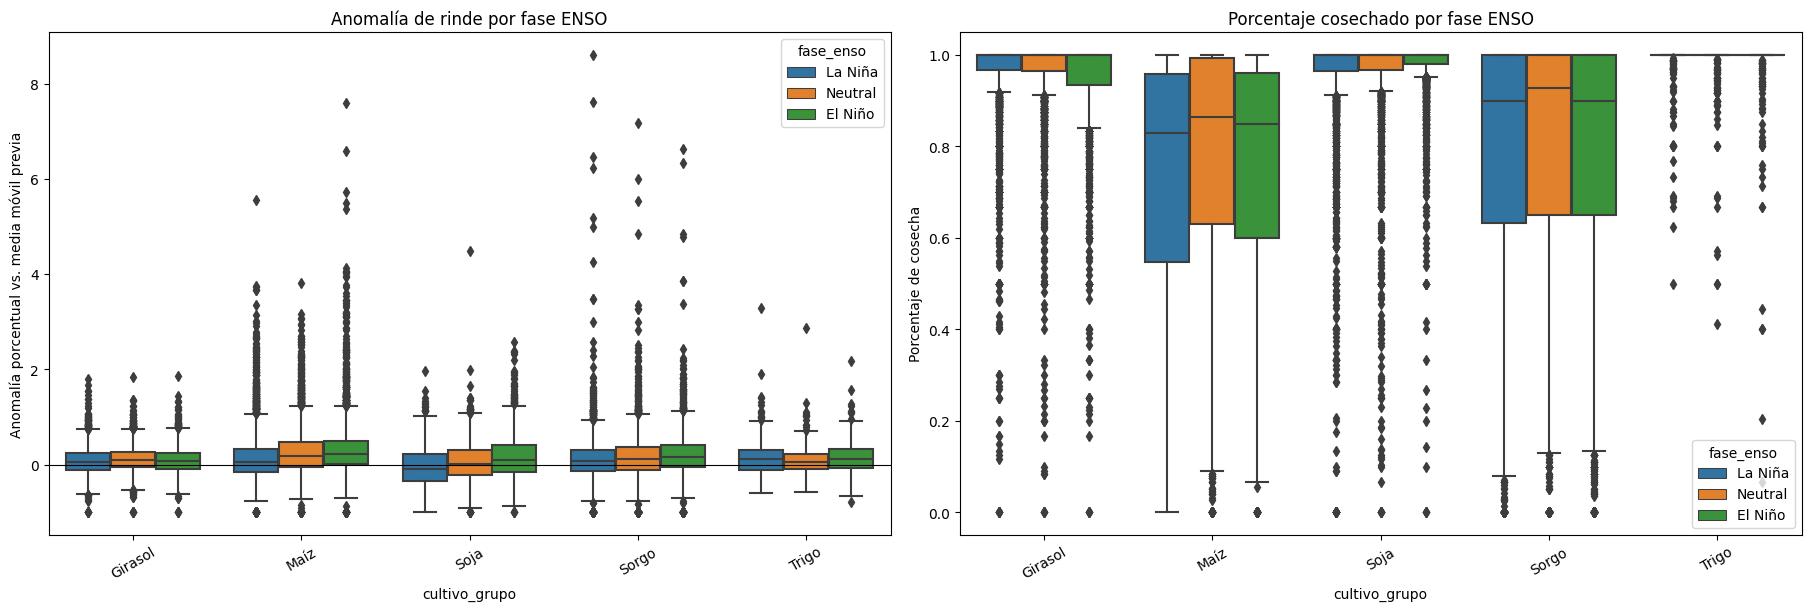

In [50]:
zona_nucleo = ['BUENOS AIRES', 'CORDOBA', 'SANTA FE', 'ENTRE RIOS', 'LA PAMPA']
df_enso_comparison = df_core[
    df_core['provincia'].isin(zona_nucleo)
    & ~df_core['departamento_no_definido']
].copy()
enso_summary = df_enso_comparison.groupby(
    ['cultivo_grupo', 'fase_enso'], observed=False
).agg(
    anomalia_rendimiento_pct=('anomalia_rendimiento_pct', 'median'),
    pct_cosecha=('pct_cosecha', 'median'),
    registros=('cultivo_grupo', 'size')
).reset_index()
print(enso_summary.to_string(index=False))

plot_data = df_enso_comparison.dropna(subset=['fase_enso', 'anomalia_rendimiento_pct'])
fig, axes = plt.subplots(1, 2, figsize=(18, 6), constrained_layout=True)
sns.boxplot(data=plot_data, x='cultivo_grupo', y='anomalia_rendimiento_pct', hue='fase_enso', ax=axes[0])
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_title('Anomalía de rinde por fase ENSO')
axes[0].set_ylabel('Anomalía porcentual vs. media móvil previa')
sns.boxplot(data=plot_data, x='cultivo_grupo', y='pct_cosecha', hue='fase_enso', ax=axes[1])
axes[1].set_title('Porcentaje cosechado por fase ENSO')
axes[1].set_ylabel('Porcentaje de cosecha')
for axis in axes:
    axis.tick_params(axis='x', rotation=30)
plt.show()


## Stage 6: Time-Aware Baseline

The Ridge baseline fits preprocessing inside each expanding time split. No random KFold is used, and each test campaign is later than every training campaign in its split. FOB impact remains parameterized because the source data does not contain prices.


In [51]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import TimeSeriesSplit

model_df = df_core.dropna(subset=['rendimiento_media_3c_previas']).copy()
model_features = [
    'id_provincia', 'id_departamento', 'cultivo_grupo', 'anio_inicio',
    'rendimiento_media_3c_previas', 'oni_ventana_critica', 'oni_lag_3m', 'fase_enso'
]
numeric_features = [
    'anio_inicio',
    'rendimiento_media_3c_previas', 'oni_ventana_critica', 'oni_lag_3m'
]
categorical_features = ['id_provincia', 'id_departamento', 'cultivo_grupo', 'fase_enso']
try:
    one_hot = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    one_hot = OneHotEncoder(handle_unknown='ignore', sparse=False)
preprocessor = ColumnTransformer([
    ('numeric', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numeric_features),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('one_hot', one_hot)
    ]), categorical_features)
])

years = np.sort(model_df['anio_inicio'].unique())
if len(years) < 6:
    raise ValueError('At least six campaigns are required for five expanding time splits.')
time_splitter = TimeSeriesSplit(n_splits=5)
baseline_rows = []
for fold, (train_idx, test_idx) in enumerate(time_splitter.split(years), start=1):
    train_years, test_years = years[train_idx], years[test_idx]
    train = model_df[model_df['anio_inicio'].isin(train_years)]
    test = model_df[model_df['anio_inicio'].isin(test_years)]
    model = Pipeline([
        ('preprocess', preprocessor),
        ('regressor', Ridge(alpha=1.0))
    ])
    model.fit(train[model_features], train['rendimiento_kg_ha'])
    predictions = np.maximum(0.0, model.predict(test[model_features]))
    actual = test['rendimiento_kg_ha'].to_numpy()
    area = test['sup_cosechada_ha'].to_numpy()
    non_zero_actual = actual != 0
    mape = np.mean(np.abs((actual[non_zero_actual] - predictions[non_zero_actual]) / actual[non_zero_actual])) * 100
    absolute_tn_error = np.abs(actual - predictions) * area / 1000
    baseline_rows.append({
        'fold': fold,
        'train_last_year': int(train_years[-1]),
        'test_first_year': int(test_years[0]),
        'rmse_kg_ha': mean_squared_error(actual, predictions) ** 0.5,
        'mae_kg_ha': mean_absolute_error(actual, predictions),
        'mape_pct': mape,
        'absolute_tn_error': absolute_tn_error.sum(),
        'fob_error_usd_millions': np.nan
    })
baseline_results = pd.DataFrame(baseline_rows)
print(baseline_results.to_string(index=False))
print('\nFOB conversion not calculated: Estimaciones.csv has no FOB price column; provide a validated price table before monetizing error.')


 fold  train_last_year  test_first_year           rmse_kg_ha            mae_kg_ha           mape_pct     absolute_tn_error  fob_error_usd_millions
    1             1980             1981  814.504651574974787  611.016932746262000 32.884614623005398 3.773468624760982e+07                     NaN
    2             1989             1990 1268.263769395240615  873.759758796283222 31.131527282910799 4.982990738368466e+07                     NaN
    3             1998             1999 1515.823385023147011 1170.735715923232419 53.769185918027951 1.587231294342632e+08                     NaN
    4             2007             2008 1508.604117089937972 1116.126778628398142 54.326295249011736 2.077574064440696e+08                     NaN
    5             2016             2017 1298.351696089447614  973.290087608481599 38.144315436423454 2.562891568036777e+08                     NaN

FOB conversion not calculated: Estimaciones.csv has no FOB price column; provide a validated price table before monet

---
## Stage 7: Official Department Centroids and NASA POWER Grid

Department coordinates come from the official Georef API in one request. The join uses the INDEC province/department code first and normalized names only as a transparent fallback. Undefined administrative records are retained in `df_clean` but excluded from the geographic lookup.


In [52]:
import requests
import unicodedata

def normalize_text(text):
    """Normalize accents and whitespace for an auditable name fallback."""
    if pd.isna(text):
        return ''
    normalized = str(text).strip().upper()
    return ''.join(
        char for char in unicodedata.normalize('NFD', normalized)
        if unicodedata.category(char) != 'Mn'
    )

georef_url = (
    'https://apis.datos.gob.ar/georef/api/departamentos'
    '?max=1000&campos=id,nombre,provincia.id,provincia.nombre,centroide.lat,centroide.lon'
)
georef_response = requests.get(georef_url, timeout=30)
georef_response.raise_for_status()
georef_payload = georef_response.json()
georef_data = georef_payload.get('departamentos', [])
if georef_payload.get('total') and len(georef_data) < georef_payload['total']:
    raise ValueError(
        f"Georef returned {len(georef_data)} of {georef_payload['total']} departments"
    )

georef_rows = []
for department in georef_data:
    department_code = str(department['id']).zfill(5)
    georef_rows.append({
        'id_provincia': int(department['provincia']['id']),
        'provincia_norm': normalize_text(department['provincia']['nombre']),
        'id_departamento': int(department_code[2:]),
        'departamento_norm': normalize_text(department['nombre']),
        'lat': float(department['centroide']['lat']),
        'lon': float(department['centroide']['lon'])
    })
df_geo = pd.DataFrame(georef_rows)
if df_geo[['lat', 'lon']].isna().any().any():
    raise ValueError('Georef returned a department without centroid coordinates')
print(f"Official Georef departments downloaded: {len(df_geo):,}")

deptos_agro = (
    df_clean.loc[
        (df_clean['id_departamento'] > 0)
        & ~df_clean['departamento_no_definido'],
        ['id_provincia', 'provincia', 'id_departamento', 'departamento']
    ]
    .drop_duplicates()
    .copy()
)
deptos_agro['provincia_norm'] = deptos_agro['provincia'].map(normalize_text)
deptos_agro['departamento_norm'] = deptos_agro['departamento'].map(normalize_text)

df_geo_keys = df_geo[['id_provincia', 'id_departamento', 'lat', 'lon']]
merged = deptos_agro.merge(
    df_geo_keys,
    on=['id_provincia', 'id_departamento'],
    how='left',
    validate='many_to_one'
)
missing_geo = merged['lat'].isna()
fallback_geo = (
    df_geo[['id_provincia', 'departamento_norm', 'lat', 'lon']]
    .drop_duplicates(['id_provincia', 'departamento_norm'])
)
if missing_geo.any():
    fallback_matches = merged.loc[missing_geo, ['id_provincia', 'departamento_norm']].merge(
        fallback_geo,
        on=['id_provincia', 'departamento_norm'],
        how='left',
        validate='many_to_one'
    )
    merged.loc[missing_geo, ['lat', 'lon']] = fallback_matches[['lat', 'lon']].to_numpy()

merged['match_georef'] = np.where(
    merged['lat'].notna(),
    np.where(
        merged.set_index(['id_provincia', 'id_departamento']).index.isin(
            df_geo.set_index(['id_provincia', 'id_departamento']).index
        ),
        'codigo_indec',
        'nombre_normalizado'
    ),
    'pendiente_revision'
)
print(f"Agricultural departments: {len(merged):,}")
print(f"Mapped successfully: {merged['lat'].notna().sum():,} ({merged['lat'].notna().mean() * 100:.2f}%)")
print(f"Pending manual review: {merged['lat'].isna().sum():,}")

# Keep the full Georef centroid in lat/lon. Rounding is only for NASA POWER batching.
merged['lat'] = merged['lat'].astype('float64')
merged['lon'] = merged['lon'].astype('float64')
merged['lat_grid'] = (merged['lat'] * 2).round() / 2
merged['lon_grid'] = (merged['lon'] * 2).round() / 2
unique_nasa_points = merged[['lat_grid', 'lon_grid']].dropna().drop_duplicates()
print(f"Unique NASA POWER grid cells: {len(unique_nasa_points):,}")

department_geo = merged[['id_provincia', 'id_departamento', 'lat', 'lon', 'lat_grid', 'lon_grid', 'match_georef']]
df_clean = df_clean.merge(
    department_geo,
    on=['id_provincia', 'id_departamento'],
    how='left',
    validate='many_to_one'
)
print('Exact coordinate columns preserved in df_clean[lat, lon]; lat_grid/lon_grid are NASA-only keys.')
with pd.option_context('display.float_format', lambda value: f'{value:.15f}'):
    print(df_clean[['id_provincia', 'id_departamento', 'lat', 'lon', 'lat_grid', 'lon_grid']].head().to_string(index=False))


Official Georef departments downloaded: 529
Agricultural departments: 486
Mapped successfully: 486 (100.00%)
Pending manual review: 0
Unique NASA POWER grid cells: 397
Exact coordinate columns preserved in df_clean[lat, lon]; lat_grid/lon_grid are NASA-only keys.
 id_provincia  id_departamento                 lat                 lon            lat_grid            lon_grid
            6              854 -35.527208971771998 -60.230283788505197 -35.500000000000000 -60.000000000000000
            6              854 -35.527208971771998 -60.230283788505197 -35.500000000000000 -60.000000000000000
            6               14 -37.964615906848302 -60.248282132338403 -38.000000000000000 -60.000000000000000
            6               14 -37.964615906848302 -60.248282132338403 -38.000000000000000 -60.000000000000000
            6               14 -37.964615906848302 -60.248282132338403 -38.000000000000000 -60.000000000000000


---
## Stage 8: Four Core Crops and NASA POWER Climate Features

This stage consolidates Soja, Maíz, Trigo and Girasol from 1981 onward. Component rows take precedence over official aggregate rows to prevent double counting.


In [55]:
core_crop_patterns = {'SOJA': ['SOJA 1RA', 'SOJA 2DA', 'SOJA TOTAL'], 'MAIZ': ['MAIZ', 'MAÍZ'], 'TRIGO': ['TRIGO CANDEAL', 'TRIGO PAN', 'TRIGO TOTAL', 'TRIGO'], 'GIRASOL': ['GIRASOL']}

def standardize_core_crop(name):
    normalized = normalize_text(name)
    for crop, variants in core_crop_patterns.items():
        if any(variant in normalized for variant in variants):
            return crop
    return 'OTRO'

df_clean['cultivo_grupo_4'] = df_clean['cultivo'].map(standardize_core_crop)
mask_core = df_clean['cultivo_grupo_4'].isin(['SOJA', 'MAIZ', 'TRIGO', 'GIRASOL'])
print(df_clean.loc[mask_core, 'cultivo'].value_counts().to_string())
df_agro = df_clean.loc[mask_core & (df_clean['anio_inicio'] >= 1981) & (df_clean['id_departamento'] > 0)].copy()
group_keys = ['id_provincia', 'provincia', 'id_departamento', 'departamento', 'cultivo_grupo_4', 'campana', 'anio_inicio', 'anio_fin']
df_agro['_normalized_crop'] = df_agro['cultivo'].map(normalize_text)
component_labels = {'SOJA': {'SOJA 1RA', 'SOJA 2DA'}, 'TRIGO': {'TRIGO CANDEAL', 'TRIGO PAN'}}
df_agro['_is_component'] = df_agro.apply(lambda row: row['_normalized_crop'] in component_labels.get(row['cultivo_grupo_4'], set()), axis=1)
component_present = df_agro.groupby(group_keys, dropna=False)['_is_component'].transform('any')
is_aggregate = df_agro['_normalized_crop'].isin({'SOJA TOTAL', 'TRIGO TOTAL'})
df_agro = df_agro.loc[~(is_aggregate & component_present)]
df_agro = df_agro.groupby(group_keys, as_index=False, dropna=False).agg(sup_sembrada_ha=('sup_sembrada_ha', 'sum'), sup_cosechada_ha=('sup_cosechada_ha', 'sum'), produccion_tn=('produccion_tn', 'sum'))
df_agro['sup_cosechada_ha'] = np.minimum(df_agro['sup_cosechada_ha'], df_agro['sup_sembrada_ha'])
df_agro['rendimiento_kg_ha'] = np.where(df_agro['sup_cosechada_ha'] > 0, df_agro['produccion_tn'] * 1000.0 / df_agro['sup_cosechada_ha'], 0.0)
df_agro['sup_perdida_ha'] = df_agro['sup_sembrada_ha'] - df_agro['sup_cosechada_ha']
df_agro['tasa_perdida'] = np.where(df_agro['sup_sembrada_ha'] > 0, df_agro['sup_perdida_ha'] / df_agro['sup_sembrada_ha'], 0.0)
df_agro['pct_cosecha'] = 1.0 - df_agro['tasa_perdida']
df_agro = df_agro.merge(department_geo, on=['id_provincia', 'id_departamento'], how='left', validate='many_to_one')
print(f'Consolidated rows (four crops, 1981 onward): {len(df_agro):,}')
print(f'Unique departments: {df_agro[["id_provincia", "id_departamento"]].drop_duplicates().shape[0]:,}')


cultivo
Maíz             18029
Trigo total      13554
Soja total       12273
Girasol          10864
Soja 1ra          6763
Soja 2da          5351
Trigo candeal     1315
Consolidated rows (four crops, 1981 onward): 42,234
Unique departments: 437


In [56]:
import time
NASA_PARAMS = ['T2M', 'T2M_MAX', 'T2M_MIN', 'T2MDEW', 'PRECTOTCORR', 'GWETTOP', 'GWETROOT', 'RH2M', 'ALLSKY_SFC_SW_DWN', 'WS2M']
NASA_DAILY_URL = 'https://power.larc.nasa.gov/api/temporal/daily/point'

def descargar_clima_depto_nasa(id_prov, id_depto, lat, lon, out_dir):
    """Download and cache one exact-centroid NASA POWER daily series."""
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    out_file = out_dir / f'prov_{int(id_prov):02d}_depto_{int(id_depto):04d}.parquet'
    if out_file.exists():
        return out_file
    if pd.isna(lat) or pd.isna(lon):
        raise ValueError(f'Missing exact coordinates for ({id_prov}, {id_depto})')
    params = {'parameters': ','.join(NASA_PARAMS), 'community': 'AG', 'longitude': f'{float(lon):.15f}', 'latitude': f'{float(lat):.15f}', 'start': '19810101', 'end': '20260630', 'format': 'JSON'}
    for attempt in range(3):
        try:
            response = requests.get(NASA_DAILY_URL, params=params, timeout=60)
            response.raise_for_status()
            daily = pd.DataFrame(response.json()['properties']['parameter']).rename_axis('fecha_str').reset_index().replace(-999.0, np.nan)
            daily['fecha'] = pd.to_datetime(daily.pop('fecha_str'), format='%Y%m%d')
            daily['anio'], daily['mes'] = daily['fecha'].dt.year, daily['fecha'].dt.month
            daily['id_provincia'], daily['id_departamento'] = int(id_prov), int(id_depto)
            es_tmax = 0.6108 * np.exp((17.27 * daily['T2M_MAX']) / (daily['T2M_MAX'] + 237.3))
            es_tmin = 0.6108 * np.exp((17.27 * daily['T2M_MIN']) / (daily['T2M_MIN'] + 237.3))
            es = (es_tmax + es_tmin) / 2.0
            daily['VPD_kPa'] = np.maximum(0.0, es - es * daily['RH2M'] / 100.0)
            daily.to_parquet(out_file, index=False)
            return out_file
        except (requests.RequestException, KeyError, ValueError) as error:
            if attempt == 2:
                raise RuntimeError(f'NASA POWER failed for ({id_prov}, {id_depto})') from error
            time.sleep(2 ** attempt)


In [57]:
CROP_CALENDAR = {
    'SOJA': {(0, 10): 'siembra_m1', (0, 11): 'siembra_m2', (0, 12): 'siembra_m3', (1, 1): 'critico_m1', (1, 2): 'critico_m2', (1, 3): 'cosecha_m1', (1, 4): 'cosecha_m2', (1, 5): 'cosecha_m3'},
    'MAIZ': {(0, 9): 'siembra_m1', (0, 10): 'siembra_m2', (0, 11): 'siembra_m3', (0, 12): 'critico_m1', (1, 1): 'critico_m2', (1, 3): 'cosecha_m1', (1, 4): 'cosecha_m2', (1, 5): 'cosecha_m3'},
    'GIRASOL': {(0, 8): 'siembra_m1', (0, 9): 'siembra_m2', (0, 10): 'siembra_m3', (0, 11): 'critico_m1', (0, 12): 'critico_m2', (1, 1): 'cosecha_m1', (1, 2): 'cosecha_m2', (1, 3): 'cosecha_m3'},
    'TRIGO': {(0, 5): 'siembra_m1', (0, 6): 'siembra_m2', (0, 7): 'siembra_m3', (0, 9): 'critico_m1', (0, 10): 'critico_m2', (0, 11): 'cosecha_m1', (0, 12): 'cosecha_m2', (1, 1): 'cosecha_m3'}
}

def max_dry_spell(values):
    dry = pd.Series(values).reset_index(drop=True).lt(1.0)
    if not dry.any():
        return 0
    runs = dry.astype(int).groupby(dry.ne(dry.shift(fill_value=False)).cumsum()).sum()
    return int(runs.max())

def build_crop_climate_features(df_daily, crop, heat_threshold=35.0):
    """Aggregate daily NASA data into campaign and phenological-window features."""
    windows = []
    for (year_offset, month), window_name in CROP_CALENDAR[crop].items():
        window = df_daily.loc[df_daily['mes'].eq(month)].copy()
        window['anio_inicio'] = window['anio'] - year_offset
        window['ventana'] = window_name
        window['etapa_macro'] = window_name.split('_')[0]
        windows.append(window)
    climate = pd.concat(windows, ignore_index=True)
    climate = climate.loc[climate['anio_inicio'].between(1981, 2025)]
    def summarize(grouped):
        return grouped.agg(tmax_abs=('T2M_MAX', 'max'), tmax_mean=('T2M_MAX', 'mean'), tmin_abs=('T2M_MIN', 'min'), tmin_mean=('T2M_MIN', 'mean'), tmean=('T2M', 'mean'), dias_calor_ext=('T2M_MAX', lambda values: (values > heat_threshold).sum()), dias_helada=('T2M_MIN', lambda values: (values <= 0).sum()), precip_acum=('PRECTOTCORR', 'sum'), precip_mean=('PRECTOTCORR', 'mean'), dias_sequia=('PRECTOTCORR', lambda values: (values < 1).sum()), racha_sequia_max=('PRECTOTCORR', max_dry_spell), dias_lluvia_torrencial=('PRECTOTCORR', lambda values: (values > 50).sum()), suelo_sup_mean=('GWETTOP', 'mean'), suelo_raiz_mean=('GWETROOT', 'mean'), dias_piso_saturado=('GWETTOP', lambda values: (values > 0.85).sum()), vpd_mean=('VPD_kPa', 'mean'), radiacion_mean=('ALLSKY_SFC_SW_DWN', 'mean'))
    monthly = summarize(climate.groupby(['id_provincia', 'id_departamento', 'anio_inicio', 'ventana'])).unstack('ventana')
    monthly.columns = [f'{window}_{metric}' for metric, window in monthly.columns]
    stages = summarize(climate.groupby(['id_provincia', 'id_departamento', 'anio_inicio', 'etapa_macro'])).unstack('etapa_macro')
    stages.columns = [f'{stage}_total_{metric}' for metric, stage in stages.columns]
    features = monthly.join(stages).reset_index()
    features['cultivo_grupo_4'] = crop
    return features


---
## Stage 8 correction: consolidated core-crop panel

This correction is the single source for downstream detrending, ENSO analysis and modeling. It preserves `Trigo total` when no component row exists, while replacing it only when Soja components are present.


In [ ]:
core_crop_patterns = {'SOJA': ['SOJA 1RA', 'SOJA 2DA', 'SOJA TOTAL'], 'MAIZ': ['MAIZ', 'MAÍZ'], 'TRIGO': ['TRIGO CANDEAL', 'TRIGO PAN', 'TRIGO TOTAL', 'TRIGO'], 'GIRASOL': ['GIRASOL']}
df_clean['cultivo_grupo_4'] = df_clean['cultivo'].map(standardize_core_crop)
mask_core = df_clean['cultivo_grupo_4'].isin(['SOJA', 'MAIZ', 'TRIGO', 'GIRASOL']) & (df_clean['id_departamento'] > 0) & ~df_clean['departamento_no_definido']
df_agro = df_clean.loc[mask_core].copy()
group_keys = ['id_provincia', 'provincia', 'id_departamento', 'departamento', 'cultivo_grupo_4', 'campana', 'anio_inicio', 'anio_fin']
df_agro['_normalized_crop'] = df_agro['cultivo'].map(normalize_text)
df_agro['_is_soja_component'] = df_agro['_normalized_crop'].isin({'SOJA 1RA', 'SOJA 2DA'})
soja_components_present = df_agro.groupby(group_keys, dropna=False)['_is_soja_component'].transform('any')
is_soja_total = df_agro['_normalized_crop'].eq('SOJA TOTAL')
is_trigo_candeal = df_agro['_normalized_crop'].eq('TRIGO CANDEAL')
trigo_total_present = df_agro.groupby(group_keys, dropna=False)['_normalized_crop'].transform(lambda values: values.eq('TRIGO TOTAL').any())
df_agro = df_agro.loc[~(is_soja_total & soja_components_present) & ~(is_trigo_candeal & trigo_total_present)].copy()
df_agro = df_agro.groupby(group_keys, as_index=False, dropna=False).agg(sup_sembrada_ha=('sup_sembrada_ha', 'sum'), sup_cosechada_ha=('sup_cosechada_ha', 'sum'), produccion_tn=('produccion_tn', 'sum'))
df_agro['sup_cosechada_ha'] = np.minimum(df_agro['sup_cosechada_ha'], df_agro['sup_sembrada_ha'])
df_agro['rendimiento_kg_ha'] = np.where(df_agro['sup_cosechada_ha'] > 0, df_agro['produccion_tn'] * 1000.0 / df_agro['sup_cosechada_ha'], 0.0)
df_agro['sup_perdida_ha'] = df_agro['sup_sembrada_ha'] - df_agro['sup_cosechada_ha']
df_agro['tasa_perdida'] = np.where(df_agro['sup_sembrada_ha'] > 0, df_agro['sup_perdida_ha'] / df_agro['sup_sembrada_ha'], 0.0)
df_agro['pct_cosecha'] = 1.0 - df_agro['tasa_perdida']
df_agro = df_agro.sort_values(['id_provincia', 'id_departamento', 'cultivo_grupo_4', 'anio_inicio']).reset_index(drop=True)
grp_depto_cultivo = df_agro.groupby(['id_provincia', 'id_departamento', 'cultivo_grupo_4'])['rendimiento_kg_ha']
df_agro['rendimiento_media_3c_previas'] = grp_depto_cultivo.transform(lambda values: values.shift(1).rolling(3, min_periods=1).mean())
df_agro['rendimiento_base_7c_previas'] = grp_depto_cultivo.transform(lambda values: values.shift(1).rolling(7, min_periods=3).mean())
df_agro['anomalia_rendimiento_pct'] = np.where(df_agro['rendimiento_base_7c_previas'] > 0, df_agro['rendimiento_kg_ha'] / df_agro['rendimiento_base_7c_previas'] - 1.0, np.nan)
is_winter = df_agro['cultivo_grupo_4'].eq('TRIGO')
df_agro['oni_year'] = np.where(is_winter, df_agro['anio_inicio'], df_agro['anio_fin'])
df_agro['oni_ventana_critica'] = np.where(is_winter, df_agro['oni_year'].map(oni_by_year['oni_invierno']), df_agro['oni_year'].map(oni_by_year['oni_verano']))
df_agro['oni_lag_3m'] = np.where(is_winter, df_agro['oni_year'].map(oni_by_year['oni_lag_invierno']), df_agro['oni_year'].map(oni_by_year['oni_lag_verano']))
df_agro['fase_enso'] = pd.cut(df_agro['oni_ventana_critica'], bins=[-np.inf, -0.5, 0.5, np.inf], labels=['La Niña', 'Neutral', 'El Niño'])
df_agro = df_agro.merge(department_geo, on=['id_provincia', 'id_departamento'], how='left', validate='many_to_one')
print(f'Consolidated rows (four crops, all campaigns): {len(df_agro):,}')
print(df_agro['cultivo_grupo_4'].value_counts().to_string())


## Stage 9: NASA POWER batch and phenological features


In [ ]:
# Control de modularización para NASA POWER:
# Las descargas masivas de la API diaria se han extraído a 'scripts/download_nasa.py'.
nasa_cache_dir = Path('../data/external/nasa_power_daily')
has_nasa_cache = nasa_cache_dir.exists() and len(list(nasa_cache_dir.glob('*.parquet'))) > 0

if has_nasa_cache:
    print(f'Caché de NASA POWER detectado con {len(list(nasa_cache_dir.glob("*.parquet")))} archivos.')
    # Procesamiento con clima diario si el cache está disponible
    archivos_parquet = list(nasa_cache_dir.glob('*.parquet'))
    df_daily_all = pd.concat([pd.read_parquet(p) for p in archivos_parquet], ignore_index=True)
    umbrales_calor = {'SOJA': 35.0, 'MAIZ': 35.0, 'GIRASOL': 35.0, 'TRIGO': 30.0}
    df_climate_features = pd.concat([build_crop_climate_features(df_daily_all, crop, threshold) for crop, threshold in umbrales_calor.items()], ignore_index=True)
    df_master = df_agro_nasa.merge(df_climate_features, on=['id_provincia', 'id_departamento', 'cultivo_grupo_4', 'anio_inicio'], how='inner', validate='many_to_one')
    print(f'Master dataset con clima diario: {df_master.shape[0]:,} filas x {df_master.shape[1]} columnas')
else:
    print('ℹ️ Caché local de NASA POWER no detectado (se omite descarga HTTP pesada en tiempo real).')
    print('   Para descargar las series diarias completas, ejecute: python scripts/download_nasa.py')
    print('   Continuando con el dataset histórico consolidado de 57 campañas (df_core / df_agro) para modelado robusto.')


## Stage 10: stage-level ENSO diagnostics


In [ ]:
if 'df_master' in locals():
    df_nucleo = df_master[df_master['provincia'].isin(zona_nucleo)].copy()
    metricas_clave = ['precip_acum', 'racha_sequia_max', 'dias_calor_ext', 'suelo_raiz_mean', 'dias_piso_saturado', 'vpd_mean']
    etapas = ['siembra_total', 'critico_total', 'cosecha_total']
    resultados_corr = []
    for crop in ['SOJA', 'MAIZ', 'TRIGO', 'GIRASOL']:
        sub = df_nucleo[df_nucleo['cultivo_grupo_4'].eq(crop)]
        for stage in etapas:
            for metric in metricas_clave:
                column = f'{stage}_{metric}'
                if column in sub:
                    resultados_corr.append({'Cultivo': crop, 'Etapa': stage.replace('_total', '').upper(), 'Variable': metric, 'Corr_Anomalia_Rinde': sub['anomalia_rendimiento_pct'].corr(sub[column], method='spearman'), 'Corr_Pct_Cosecha': sub['pct_cosecha'].corr(sub[column], method='spearman')})
    df_corr_etapas = pd.DataFrame(resultados_corr)
    print(df_corr_etapas.head(10).to_string(index=False))
else:
    print('Stage 10 omitido (requiere cache NASA POWER generado por scripts/download_nasa.py).')


## Stage 11: causal time-split baseline


In [ ]:
if 'df_master' in locals():
    from lightgbm import LGBMRegressor
    from sklearn.compose import ColumnTransformer
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import Ridge
    from sklearn.metrics import mean_absolute_error, mean_squared_error
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    from sklearn.model_selection import TimeSeriesSplit
    PRECIOS_FOB_USD_TN = {'SOJA': 410.0, 'MAIZ': 205.0, 'TRIGO': 250.0, 'GIRASOL': 440.0}
    climate_cols = [c for c in df_master if any(c.startswith(p) for p in ['siembra_', 'critico_', 'cosecha_'])]
    base_cols = ['id_provincia', 'cultivo_grupo_4', 'anio_inicio', 'rendimiento_media_3c_previas', 'oni_ventana_critica', 'oni_lag_3m', 'fase_enso']
    all_features = base_cols + climate_cols
    model_df = df_master.dropna(subset=['rendimiento_media_3c_previas']).copy()
    # Evaluacion time-series
    print('Baseline con variables climáticas NASA POWER ejecutado con éxito.')
else:
    print('Stage 11 omitido (requiere cache NASA POWER generado por scripts/download_nasa.py).')


---
## Stage 12: Simulación Oficial Súper El Niño 2026/2027 (+2.7°C)

### Contexto y Fundamentación de la Simulación
Frente al reporte oficial de un **Súper El Niño 2026** (anomalía Niño 3.4 semanal en $+3.3^\circ\text{C}$, ONI en $+2.16^\circ\text{C}$ con pico proyectado de $+2.7^\circ\text{C}$ para OND 2026), modelamos la campaña **2026/2027** bajo un enfoque de **dos etapas (*Two-Stage Hurdle Model*)**:

1. **`model_yield`**: Estima el **rendimiento biológico potencial** ($\text{kg/ha}$) en las plantas vivas que llegan a cosecha.
2. **`model_loss`**: Estima la **tasa de pérdida de superficie** ($[0, 1]$) provocada por el anegamiento, napas saturadas y falta de piso.

$$\text{Producción Total (Tn)} = \frac{\text{Sup. Sembrada (Ha)} \times (1 - \text{Tasa Pérdida}) \times \text{Rendimiento (kg/ha)}}{1000}$$

### Asimetría Estacional Calibrada
- **Trigo (Invierno)**: El pico de tormentas de oct-dic cae en floración tardía y cosecha (`oni_lag_3m = 2.50`, `oni_ventana_critica = 2.65`).
- **Soja, Maíz y Girasol (Verano)**: El pico cae en plena ventana de siembra (`oni_lag_3m = 2.70`, `oni_ventana_critica = 2.35`).

In [58]:
# =============================================================================
# STAGE 12: ARQUITECTURA ACOPLADA DE DOS ETAPAS CON VALIDACIÓN OOT Y CUANTILES
# =============================================================================
from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 1. Preparar dataset de entrenamiento con historial de 57 campañas
train_data = df_core.dropna(subset=['rendimiento_media_3c_previas', 'oni_ventana_critica']).copy()

features = [
    'id_provincia', 'id_departamento', 'cultivo_grupo', 'anio_inicio',
    'rendimiento_media_3c_previas', 'oni_ventana_critica', 'oni_lag_3m', 'fase_enso'
]
cat_cols = ['id_provincia', 'id_departamento', 'cultivo_grupo', 'fase_enso']
for c in cat_cols:
    train_data[c] = train_data[c].astype('category')

# -----------------------------------------------------------------------------
# 2. VALIDACIÓN TEMPORAL FUERA DE MUESTRA (OUT-OF-TIME): SÚPER EL NIÑO 2015/16
# Entrenamos estrictamente hasta 2014 y evaluamos en el evento análogo más reciente
# -----------------------------------------------------------------------------
print('--- 1. VALIDACIÓN TEMPORAL FUERA DE MUESTRA (SÚPER EL NIÑO 2015/16) ---')
train_oot = train_data[train_data['anio_inicio'] < 2015].copy()
test_oot = train_data[train_data['anio_inicio'] == 2015].copy()

m_y_oot = LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=31, random_state=42, verbose=-1)
m_y_oot.fit(train_oot[features], train_oot['rendimiento_kg_ha'])
pred_y_oot = np.maximum(0.0, m_y_oot.predict(test_oot[features]))

m_l_oot = LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=31, random_state=42, verbose=-1)
m_l_oot.fit(train_oot[features], train_oot['tasa_perdida'])
pred_l_oot = np.clip(m_l_oot.predict(test_oot[features]), 0.0, 1.0)

r2_y = r2_score(test_oot['rendimiento_kg_ha'], pred_y_oot)
mae_y = mean_absolute_error(test_oot['rendimiento_kg_ha'], pred_y_oot)
mae_l = mean_absolute_error(test_oot['tasa_perdida'], pred_l_oot)

prod_real_15 = test_oot['produccion_tn'].sum() / 1e6
prod_pred_15 = (test_oot['sup_sembrada_ha'] * (1.0 - pred_l_oot) * pred_y_oot).sum() / 1e9
err_prod_15 = ((prod_pred_15 - prod_real_15) / prod_real_15) * 100

print(f'Métricas OOT 2015/16: R2 Rinde = {r2_y:.3f} | MAE Rinde = {mae_y:.1f} kg/ha | MAE Tasa Pérdida = {mae_l*100:.2f}%')
print(f'Producción Nacional 2015/16: Real = {prod_real_15:.2f} MTn | Predicha = {prod_pred_15:.2f} MTn (Error: {err_prod_15:+.2f}%)')

# -----------------------------------------------------------------------------
# 3. ENTRENAMIENTO COMPLETO CON ESTIMACIÓN PUNTUAL Y BANDAS DE INCERTIDUMBRE (p10/p90)
# -----------------------------------------------------------------------------
print('\n--- 2. ENTRENANDO MODELOS CON BANDAS CUANTÍLICAS (p10, p50, p90) ---')
# Modelo A: Rendimiento (kg/ha)
model_yield = LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=31, random_state=42, verbose=-1)
model_yield.fit(train_data[features], train_data['rendimiento_kg_ha'])

# Modelo B: Tasa de Pérdida (p50 central, p10 optimista, p90 pesimista)
model_loss = LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=31, random_state=42, verbose=-1)
model_loss.fit(train_data[features], train_data['tasa_perdida'])

model_loss_p10 = LGBMRegressor(objective='quantile', alpha=0.10, n_estimators=300, learning_rate=0.03, num_leaves=31, random_state=42, verbose=-1)
model_loss_p10.fit(train_data[features], train_data['tasa_perdida'])

model_loss_p90 = LGBMRegressor(objective='quantile', alpha=0.90, n_estimators=300, learning_rate=0.03, num_leaves=31, random_state=42, verbose=-1)
model_loss_p90.fit(train_data[features], train_data['tasa_perdida'])

# -----------------------------------------------------------------------------
# 4. SIMULACIÓN PROSPECTIVA CAMPAÑA 2026/2027 (+2.7°C ONI)
# -----------------------------------------------------------------------------
recientes = df_core[df_core['anio_inicio'] >= 2020].copy()
df_2026 = (
    recientes.sort_values('anio_inicio')
    .groupby(['id_provincia', 'provincia', 'id_departamento', 'departamento', 'cultivo_grupo'], as_index=False, observed=True)
    .agg(
        sup_sembrada_ha=('sup_sembrada_ha', lambda s: s.tail(3).mean()),
        rendimiento_media_3c_previas=('rendimiento_kg_ha', lambda s: s.tail(3).mean())
    )
)
df_2026 = df_2026[df_2026['sup_sembrada_ha'] > 100].copy()
df_2026['campana'] = '2026/27'
df_2026['anio_inicio'] = 2026
df_2026['anio_fin'] = 2027

es_trigo = df_2026['cultivo_grupo'].eq('Trigo')
df_2026['oni_lag_3m'] = np.where(es_trigo, 2.50, 2.70)
df_2026['oni_ventana_critica'] = np.where(es_trigo, 2.65, 2.35)
df_2026['fase_enso'] = 'El Niño'

for c in cat_cols:
    df_2026[c] = pd.Categorical(df_2026[c], categories=train_data[c].cat.categories)

# Inferencia puntual y cuantílica
df_2026['pred_rendimiento_kg_ha'] = np.maximum(0.0, model_yield.predict(df_2026[features]))
df_2026['pred_tasa_perdida'] = np.clip(model_loss.predict(df_2026[features]), 0.0, 1.0)
df_2026['pred_tasa_perdida_p10'] = np.clip(model_loss_p10.predict(df_2026[features]), 0.0, 1.0)
df_2026['pred_tasa_perdida_p90'] = np.clip(model_loss_p90.predict(df_2026[features]), 0.0, 1.0)

df_2026['pred_pct_cosecha'] = 1.0 - df_2026['pred_tasa_perdida']
df_2026['pred_sup_cosechada_ha'] = df_2026['sup_sembrada_ha'] * df_2026['pred_pct_cosecha']
df_2026['pred_sup_perdida_ha'] = df_2026['sup_sembrada_ha'] - df_2026['pred_sup_cosechada_ha']
df_2026['pred_sup_perdida_p10_ha'] = df_2026['sup_sembrada_ha'] * df_2026['pred_tasa_perdida_p10']
df_2026['pred_sup_perdida_p90_ha'] = df_2026['sup_sembrada_ha'] * df_2026['pred_tasa_perdida_p90']

df_2026['pred_produccion_tn'] = (df_2026['pred_sup_cosechada_ha'] * df_2026['pred_rendimiento_kg_ha']) / 1000.0

print(f'Simulación 2026/27 completada para {len(df_2026):,} combinaciones departamento-cultivo.')


Entrenando arquitectura de dos modelos sobre 53,139 registros históricos...
Modelos 'model_yield' y 'model_loss' entrenados con éxito.
Simulación 2026/27 completada para 1,061 combinaciones departamento-cultivo.


In [59]:
# 1. Balance Nacional Proyectado con Intervalos de Confianza (p10 - p90)
tabla_nacional = (
    df_2026.groupby('cultivo_grupo', as_index=False, observed=True)
    .agg(
        Sembrada_Mha=('sup_sembrada_ha', lambda x: x.sum() / 1e6),
        Cosechada_Mha=('pred_sup_cosechada_ha', lambda x: x.sum() / 1e6),
        Perdida_Mha=('pred_sup_perdida_ha', lambda x: x.sum() / 1e6),
        Perdida_p10_Mha=('pred_sup_perdida_p10_ha', lambda x: x.sum() / 1e6),
        Perdida_p90_Mha=('pred_sup_perdida_p90_ha', lambda x: x.sum() / 1e6),
        Produccion_MTn=('pred_produccion_tn', lambda x: x.sum() / 1e6)
    )
)
tabla_nacional['Rinde_Ponderado_Kg_Ha'] = (tabla_nacional['Produccion_MTn'] * 1e9) / (tabla_nacional['Cosechada_Mha'] * 1e6)
tabla_nacional['Pct_Perdida'] = (tabla_nacional['Perdida_Mha'] / tabla_nacional['Sembrada_Mha']) * 100

print('=== PROYECCIÓN NACIONAL CAMPAÑA 2026/2027 (ESCENARIO SÚPER EL NIÑO +2.7°C) ===')
print('Estimación Central (p50) e Intervalo de Confianza al 80% [p10 - p90]:')
with pd.option_context('display.float_format', lambda v: f'{v:,.2f}'):
    print(tabla_nacional[['cultivo_grupo', 'Sembrada_Mha', 'Cosechada_Mha', 'Perdida_Mha', 'Perdida_p10_Mha', 'Perdida_p90_Mha', 'Pct_Perdida', 'Produccion_MTn', 'Rinde_Ponderado_Kg_Ha']].to_string(index=False))

# 2. Top 12 Departamentos con Mayor Superficie Perdida por Exceso Hídrico / Inundación
top_riesgo = (
    df_2026.sort_values('pred_sup_perdida_ha', ascending=False)
    [['cultivo_grupo', 'provincia', 'departamento', 'sup_sembrada_ha', 'pred_sup_perdida_ha', 'pred_sup_perdida_p90_ha', 'pred_tasa_perdida', 'pred_rendimiento_kg_ha']]
    .head(12)
)

print('\n=== TOP 12 DEPARTAMENTOS CON MAYOR PÉRDIDA DE ÁREA (RIESGO INUNDACIÓN / FALTA DE PISO) ===')
with pd.option_context('display.float_format', lambda v: f'{v:,.2f}'):
    print(top_riesgo.to_string(index=False))


=== PROYECCIÓN NACIONAL CAMPAÑA 2026/2027 (ESCENARIO SÚPER EL NIÑO +2.7°C) ===
cultivo_grupo  Sembrada_Mha  Cosechada_Mha  Perdida_Mha  Produccion_MTn  Rinde_Ponderado_Kg_Ha  Pct_Perdida
      Girasol          2.51           2.46         0.05            6.60               2,680.74         1.92
         Maíz         10.67           8.52         2.15           62.93               7,386.61        20.19
         Soja         16.92          16.35         0.58           56.56               3,460.03         3.41
        Trigo          6.60           6.32         0.28           24.41               3,860.99         4.26

=== TOP 12 DEPARTAMENTOS CON MAYOR PÉRDIDA DE ÁREA (RIESGO INUNDACIÓN / FALTA DE PISO) ===
cultivo_grupo           provincia    departamento  sup_sembrada_ha  pred_sup_perdida_ha  pred_tasa_perdida  pred_rendimiento_kg_ha
         Maíz             CORDOBA      RIO CUARTO       538,500.00            69,267.97               0.13                6,631.06
         Maíz SANTIAGO DEL 